# Highest-Grossing Films: What Makes a Box-Office Hit?

## Task 1. Data sources

In [1]:
import difflib
import json
import os
import re
import time
import unicodedata
from datetime import datetime
from pathlib import Path
from urllib.parse import urlparse
from urllib.robotparser import RobotFileParser

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

DATA_RAW, DATA_PROCESSED, FIGURES = Path("data/raw"), Path("data/processed"), Path("figures")
for folder in (DATA_RAW, DATA_PROCESSED, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 30)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})

USER_AGENT = "KBTU-DataCollection-SIS/1.0 (student project; python-requests)"
retry = Retry(total=5, backoff_factor=1.0, status_forcelist=(429, 500, 502, 503, 504), allowed_methods=("GET",))
session = requests.Session()
session.headers.update({"User-Agent": USER_AGENT})
session.mount("https://", HTTPAdapter(max_retries=retry))

key_file = Path("tmdb_api_key.txt")
TMDB_API_KEY = os.environ.get("TMDB_API_KEY") or (key_file.read_text().strip() if key_file.exists() else "")
if not TMDB_API_KEY:
    raise RuntimeError("Set TMDB_API_KEY or create tmdb_api_key.txt with your TMDb key")

print("Collected on:", datetime.now().strftime("%Y-%m-%d %H:%M"))
print("TMDb key loaded:", bool(TMDB_API_KEY), "| length:", len(TMDB_API_KEY))

Collected on: 2026-10-07 12:30
TMDb key loaded: True | length: 32


## Task 2. Web scraping

In [2]:
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_highest-grossing_films"

parts = urlparse(WIKI_URL)
robots_url = f"{parts.scheme}://{parts.netloc}/robots.txt"
robots = RobotFileParser()
robots.parse(session.get(robots_url, timeout=30).text.splitlines())

allowed = robots.can_fetch(USER_AGENT, WIKI_URL)
print("robots.txt:", robots_url)
print("Allowed to fetch the page:", allowed)
if not allowed:
    raise PermissionError("Scraping is not allowed by robots.txt")

robots.txt: https://en.wikipedia.org/robots.txt
Allowed to fetch the page: True


In [3]:
page = session.get(WIKI_URL, timeout=30)
page.raise_for_status()
(DATA_RAW / "wikipedia_highest_grossing.html").write_text(page.text, encoding="utf-8")

soup = BeautifulSoup(page.text, "html.parser")
tables = soup.select("table.wikitable")

print("Status code:", page.status_code)
print("Page size (characters):", len(page.text))
print("Title:", soup.title.get_text() if soup.title else "(no title)")
print("Tables with class 'wikitable':", len(tables))

Status code: 200
Page size (characters): 2207972
Title: List of highest-grossing films - Wikipedia
Tables with class 'wikitable': 88


In [4]:
FOOTNOTE = re.compile(r"\[[^\]]*\]")


def clean_text(text: str) -> str:
    text = FOOTNOTE.sub("", text).replace("\xa0", " ")
    return re.sub(r"\s+", " ", text).strip()


def table_to_grid(table):
    grid, is_data_row, carried = [], [], {}
    for r, tr in enumerate(table.find_all("tr")):
        row, col = [], 0
        for cell in tr.find_all(["th", "td"], recursive=False):
            while (r, col) in carried:
                row.append(carried.pop((r, col)))
                col += 1
            text = clean_text(cell.get_text(" ", strip=True))
            colspan = int(re.sub(r"\D", "", cell.get("colspan", "1")) or 1)
            rowspan = int(re.sub(r"\D", "", cell.get("rowspan", "1")) or 1)
            for _ in range(colspan):
                row.append(text)
                for extra in range(1, rowspan):
                    carried[(r + extra, col)] = text
                col += 1
        while (r, col) in carried:
            row.append(carried.pop((r, col)))
            col += 1
        grid.append(row)
        is_data_row.append(tr.find("td", recursive=False) is not None)
    return grid, is_data_row

In [5]:
def find_table(tables, required_words):
    for table in tables:
        grid, is_data_row = table_to_grid(table)
        header_rows = [row for row, is_data in zip(grid, is_data_row) if not is_data]
        data_rows = [row for row, is_data in zip(grid, is_data_row) if is_data]
        if not header_rows or not data_rows:
            continue
        n_cols = max(len(row) for row in grid)
        labels = [" ".join(dict.fromkeys(h[c] for h in header_rows if c < len(h) and h[c])).lower()
                  for c in range(n_cols)]
        if all(any(word in label for label in labels) for word in required_words):
            return labels, data_rows
    raise ValueError(f"No table with columns {required_words} - the page layout may have changed")


def column(labels, word):
    return next(i for i, label in enumerate(labels) if word in label)


top_labels, top_rows = find_table(tables, ["rank", "peak", "title", "worldwide gross"])
year_labels, year_rows = find_table(tables, ["year", "title", "worldwide gross", "budget"])
print("Table 1 columns:", top_labels, "| rows:", len(top_rows))
print("Table 2 columns:", year_labels, "| rows:", len(year_rows))
print()
print("Example row (table 1):", top_rows[4])
print("Example row (table 2):", year_rows[0])

Table 1 columns: ['rank', 'peak', 'title', 'worldwide gross', 'year', 'ref'] | rows: 50
Table 2 columns: ['year', 'title', 'worldwide gross', 'budget', 'references'] | rows: 153

Example row (table 1): ['5', '1', 'Titanic', 'T $ 2,257,906,828', '1997', '']
Example row (table 2): ['1915', 'The Birth of a Nation', '$50,000,000 – 100,000,000 $20,000,000 + R ( $5,200,000 ) R', '$110,000', '']


In [6]:
c = {w: column(top_labels, w) for w in ["rank", "peak", "title", "worldwide gross", "year"]}
top_raw = pd.DataFrame([
    {"rank": r[c["rank"]], "peak": r[c["peak"]], "title": r[c["title"]],
     "gross_text": r[c["worldwide gross"]], "year": r[c["year"]]}
    for r in top_rows if len(r) > max(c.values())
])

c = {w: column(year_labels, w) for w in ["year", "title", "worldwide gross", "budget"]}
year_raw = pd.DataFrame([
    {"year": r[c["year"]], "title": r[c["title"]], "gross_text": r[c["worldwide gross"]],
     "budget_text": r[c["budget"]]}
    for r in year_rows if len(r) > max(c.values())
])

print("Top films:", top_raw.shape, "| films by year:", year_raw.shape)
top_raw.head(6)

Top films: (50, 5) | films by year: (153, 4)


,rank,peak,title,gross_text,year
0,1,1,Avengers: Endgame †,"$2,926,059,126",2019
1,2,1,Avatar,"$2,923,710,708",2009
2,3,3,Spider-Man: Brand New Day †,"$2,506,251,053",2026
3,4,3,Avatar: The Way of Water,"$2,334,484,620",2022
4,5,1,Titanic,"T $ 2,257,906,828",1997
5,6,5,Ne Zha 2,"NZ $ 2,217,758,382",2025


In [7]:
year_raw.head(6)

,year,title,gross_text,budget_text
0,1915,The Birth of a Nation,"$50,000,000 – 100,000,000 ...","$110,000"
1,1916,Intolerance,"$1,750,000 R IN","$385,907"
2,1917,Cleopatra,"$500,000 * R","$300,000"
3,1918,Mickey,"$8,000,000","$250,000"
4,1919,The Miracle Man,"$3,000,000 R","$120,000"
5,1920,Way Down East,"$5,000,000 R ( $4,000,000 ) R","$800,000"


## Task 3. Cleaning the web data

In [8]:
MONEY = re.compile(r"\$\s?(\d[\d,]*(?:\.\d+)?)(?:\s*[–-]\s*\$?(\d[\d,]*(?:\.\d+)?))?\s*(million|billion)?", re.I)


def parse_money(text: str) -> float:
    match = MONEY.search(str(text))
    if not match:
        return np.nan
    low = float(match.group(1).replace(",", ""))
    high = float(match.group(2).replace(",", "")) if match.group(2) else low
    multiplier = {"million": 1e6, "billion": 1e9}.get((match.group(3) or "").lower(), 1)
    return (low + high) / 2 * multiplier


for example in ["T $2,257,906,828", "$128,000,000–145,000,000", "$1,750,000 R IN", "$2.8 million", "N/A"]:
    print(f"{example!r:<30} -> {parse_money(example):,.0f}")

'T $2,257,906,828'             -> 2,257,906,828
'$128,000,000–145,000,000'     -> 136,500,000
'$1,750,000 R IN'              -> 1,750,000
'$2.8 million'                 -> 2,800,000
'N/A'                          -> nan


In [9]:
def clean_title(title: str) -> str:
    return re.sub(r"\s+", " ", re.sub(r"[†‡*#]", "", title)).strip()


def to_int(text) -> "int | None":
    match = re.search(r"\d+", str(text))
    return int(match.group()) if match else None


top = top_raw.copy()
top["in_theaters"] = top["title"].str.contains("†")
top["title"] = top["title"].map(clean_title)
top["rank"] = top["rank"].map(to_int).astype("Int64")
top["peak"] = top["peak"].map(to_int).astype("Int64")
top["year"] = top["year"].map(to_int).astype("Int64")
top["worldwide_gross"] = top["gross_text"].map(parse_money)
top = top.drop(columns="gross_text")

print(top.dtypes)
print("Still in cinemas:", top.loc[top["in_theaters"], "title"].tolist())
top.head()

rank                 Int64
peak                 Int64
title               object
year                 Int64
in_theaters           bool
worldwide_gross    float64
dtype: object
Still in cinemas: ['Avengers: Endgame', 'Spider-Man: Brand New Day', 'The Odyssey', 'Toy Story 5']


,rank,peak,title,year,in_theaters,worldwide_gross
0,1,1,Avengers: Endgame,2019,True,2.926059e+09
1,2,1,Avatar,2009,False,2.923711e+09
2,3,3,Spider-Man: Brand New Day,2026,True,2.506251e+09
3,4,3,Avatar: The Way of Water,2022,False,2.334485e+09
4,5,1,Titanic,1997,False,2.257907e+09


In [10]:
by_year = year_raw.copy()
by_year["in_theaters"] = by_year["title"].str.contains("†")
by_year["title"] = by_year["title"].map(clean_title)
by_year["year"] = by_year["year"].map(to_int).astype("Int64")
by_year["worldwide_gross"] = by_year["gross_text"].map(parse_money)
by_year["budget_wiki"] = by_year["budget_text"].map(parse_money)
by_year["budget_is_range"] = by_year["budget_text"].str.contains(r"\d\s*[–-]\s*\$?\d", regex=True)
by_year = by_year.drop(columns=["gross_text", "budget_text"])

print("Missing values:")
print(by_year.isna().sum())
by_year.head()

Missing values:
year               0
title              0
in_theaters        0
worldwide_gross    0
budget_wiki        0
budget_is_range    0
dtype: int64


,year,title,in_theaters,worldwide_gross,budget_wiki,budget_is_range
0,1915,The Birth of a Nation,False,75000000.0,110000.0,False
1,1916,Intolerance,False,1750000.0,385907.0,False
2,1917,Cleopatra,False,500000.0,300000.0,False
3,1918,Mickey,False,8000000.0,250000.0,False
4,1919,The Miracle Man,False,3000000.0,120000.0,False


In [11]:
def title_key(title: str) -> str:
    text = unicodedata.normalize("NFKD", str(title)).encode("ascii", "ignore").decode("ascii").lower()
    text = text.replace("&", "and")
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", text)).strip()


top["is_top50"], top["is_year_leader"] = True, False
by_year["is_top50"], by_year["is_year_leader"] = False, True
films_wiki = pd.concat([top, by_year], ignore_index=True)
films_wiki["film_key"] = films_wiki["title"].map(title_key) + "_" + films_wiki["year"].astype(str)

print("Rows before removing duplicates:", len(films_wiki))
films_wiki = (
    films_wiki.groupby("film_key", as_index=False)
    .agg(title=("title", "first"), year=("year", "first"), rank=("rank", "min"), peak=("peak", "min"),
         worldwide_gross=("worldwide_gross", "max"), budget_wiki=("budget_wiki", "first"),
         budget_is_range=("budget_is_range", "first"), in_theaters=("in_theaters", "max"),
         is_top50=("is_top50", "any"), is_year_leader=("is_year_leader", "any"))
    .sort_values("worldwide_gross", ascending=False).reset_index(drop=True)
)
print("Unique films:", len(films_wiki))
print("In both tables:", (films_wiki["is_top50"] & films_wiki["is_year_leader"]).sum())
films_wiki[["title", "year", "rank", "worldwide_gross", "budget_wiki"]].head()

Rows before removing duplicates: 203
Unique films: 183
In both tables: 20


,title,year,rank,worldwide_gross,budget_wiki
0,Avengers: Endgame,2019,1,2.926059e+09,356000000.0
1,Avatar,2009,2,2.923711e+09,237000000.0
2,Spider-Man: Brand New Day,2026,3,2.506251e+09,225000000.0
3,Avatar: The Way of Water,2022,4,2.334485e+09,405000000.0
4,Titanic,1997,5,2.257907e+09,200000000.0


In [12]:
films_wiki.to_csv(DATA_PROCESSED / "wikipedia_films.csv", index=False)
print(films_wiki.shape)
print("Missing values:", int(films_wiki[["title", "year", "worldwide_gross"]].isna().sum().sum()))

(183, 11)
Missing values: 0


## Task 4. API data collection

In [13]:
TMDB_BASE_URL = "https://api.themoviedb.org/3"
USE_BEARER = len(TMDB_API_KEY) > 40


def tmdb_get(path: str, params: dict | None = None) -> requests.Response:
    params = dict(params or {})
    headers = {"accept": "application/json"}
    if USE_BEARER:
        headers["Authorization"] = f"Bearer {TMDB_API_KEY}"
    else:
        params["api_key"] = TMDB_API_KEY
    return session.get(f"{TMDB_BASE_URL}{path}", params=params, headers=headers, timeout=30)


response = tmdb_get("/search/movie", {"query": "Avatar", "year": 2009})
print("Status code:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))

Status code: 200
Content type: application/json;charset=utf-8


In [14]:
data = response.json()
print("Top-level keys:", list(data.keys()))
print("Results found:", data["total_results"])
print()
first = data["results"][0]
print("Keys inside one result:", list(first.keys()))
for result in data["results"][:3]:
    print(result["id"], "|", result["title"], "|", result["release_date"], "|", result["vote_average"])

Top-level keys: ['page', 'results', 'total_pages', 'total_results']
Results found: 5

Keys inside one result: ['adult', 'backdrop_path', 'genre_ids', 'id', 'title', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'release_date', 'softcore', 'video', 'vote_average', 'vote_count']
19995 | Avatar | 2009-12-16 | 7.61
287003 | Avatar: Scene Deconstruction | 2009-12-18 | 6.5
287004 | Avatar: Production Materials | 2009-12-18 | 5.7


In [15]:
details = tmdb_get(f"/movie/{first['id']}").json()
print("Number of fields:", len(details))
for field in ["title", "release_date", "budget", "revenue", "runtime", "vote_average", "vote_count", "original_language"]:
    print(f"{field}: {details.get(field)}")
print("genres:", [g["name"] for g in details.get("genres", [])])

Number of fields: 27
title: Avatar
release_date: 2009-12-16
budget: 237000000
revenue: 2923706026
runtime: 162
vote_average: 7.6
vote_count: 34789
original_language: en
genres: ['Science Fiction', 'Action', 'Adventure']


In [16]:
def match_score(wiki_title: str, wiki_year: int, result: dict) -> float:
    similarity = difflib.SequenceMatcher(None, title_key(wiki_title), title_key(result.get("title", ""))).ratio()
    result_year = to_int(result.get("release_date", "")[:4])
    year_bonus = 0.3 if result_year == wiki_year else 0.15 if result_year and abs(result_year - wiki_year) == 1 else 0
    return similarity + year_bonus


def search_movie(title: str, year: int) -> tuple[dict | None, float]:
    results = tmdb_get("/search/movie", {"query": title, "year": year}).json().get("results", [])
    if not results:
        results = tmdb_get("/search/movie", {"query": title}).json().get("results", [])
    if not results:
        return None, 0.0
    best = max(results[:10], key=lambda r: (match_score(title, year, r), r.get("vote_count", 0)))
    return best, round(match_score(title, year, best), 3)


best, score = search_movie("Titanic", 1997)
print("Titanic 1997 ->", best["id"], best["title"], best["release_date"], "| score:", score)

Titanic 1997 -> 597 Titanic 1997-12-18 | score: 1.3


In [17]:
raw_tmdb, failed = [], []
for film in films_wiki.itertuples():
    found, score = search_movie(film.title, int(film.year))
    if found is None:
        failed.append(film.title)
        continue
    r = tmdb_get(f"/movie/{found['id']}")
    if r.status_code != 200:
        failed.append(film.title)
        continue
    raw_tmdb.append({"film_key": film.film_key, "match_score": score, "details": r.json()})
    time.sleep(0.1)

(DATA_RAW / "tmdb_movies.json").write_text(json.dumps(raw_tmdb), encoding="utf-8")
print("Films found:", len(raw_tmdb), "of", len(films_wiki))
print("Not found:", failed)

Films found: 183 of 183
Not found: []


In [18]:
api_raw = pd.DataFrame([
    {
        "film_key": item["film_key"],
        "match_score": item["match_score"],
        "tmdb_id": d.get("id"),
        "tmdb_title": d.get("title"),
        "release_date": d.get("release_date"),
        "budget_tmdb": d.get("budget"),
        "revenue_tmdb": d.get("revenue"),
        "runtime": d.get("runtime"),
        "vote_average": d.get("vote_average"),
        "vote_count": d.get("vote_count"),
        "popularity": d.get("popularity"),
        "original_language": d.get("original_language"),
        "genres": "|".join(g["name"] for g in d.get("genres") or []),
        "main_company": (d.get("production_companies") or [{}])[0].get("name"),
    }
    for item in raw_tmdb
    for d in [item["details"]]
])
print(api_raw.shape)
api_raw.head()

(183, 14)


,film_key,match_score,tmdb_id,tmdb_title,release_date,budget_tmdb,...,vote_average,vote_count,popularity,original_language,genres,main_company
0,avengers endgame_2019,1.3,299534,Avengers: Endgame,2019-04-24,356000000,...,8.246,28926,101.2239,en,Adventure|Science Fiction|...,Marvel Studios
1,avatar_2009,1.3,19995,Avatar,2009-12-16,237000000,...,7.600,34789,47.0545,en,Science Fiction|Action|Adv...,Dune Entertainment
2,spider man brand new day_2026,1.3,969681,Spider-Man: Brand New Day,2026-07-29,225000000,...,8.221,3962,911.1835,en,Science Fiction|Action|Adv...,Marvel Studios
3,avatar the way of water_2022,1.3,76600,Avatar: The Way of Water,2022-12-14,460000000,...,7.600,14723,37.9436,en,Action|Adventure|Science F...,20th Century Studios
4,titanic_1997,1.3,597,Titanic,1997-12-18,200000000,...,7.901,27850,39.7197,en,Drama|Romance,Paramount Pictures


## Task 5. Cleaning the API data

In [19]:
api_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 183 entries, 0 to 182
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   film_key           183 non-null    object 
 1   match_score        183 non-null    float64
 2   tmdb_id            183 non-null    int64  
 3   tmdb_title         183 non-null    object 
 4   release_date       183 non-null    object 
 5   budget_tmdb        183 non-null    int64  
 6   revenue_tmdb       183 non-null    int64  
 7   runtime            183 non-null    int64  
 8   vote_average       183 non-null    float64
 9   vote_count         183 non-null    int64  
 10  popularity         183 non-null    float64
 11  original_language  183 non-null    object 
 12  genres             183 non-null    object 
 13  main_company       182 non-null    object 
dtypes: float64(3), int64(5), object(6)
memory usage: 20.1+ KB


In [20]:
print("Zero values (hidden missing data):")
print((api_raw[["budget_tmdb", "revenue_tmdb", "runtime"]] == 0).sum())
print()
print("Empty strings:", (api_raw[["genres", "release_date"]] == "").sum().to_dict())
print("Duplicated TMDb ids:", api_raw["tmdb_id"].duplicated().sum())

Zero values (hidden missing data):
budget_tmdb     20
revenue_tmdb    16
runtime          0
dtype: int64

Empty strings: {'genres': 0, 'release_date': 0}
Duplicated TMDb ids: 0


In [21]:
api = api_raw.copy()
for col in ["budget_tmdb", "revenue_tmdb", "runtime"]:
    api[col] = api[col].replace(0, np.nan)
api = api.replace({"genres": {"": np.nan}, "release_date": {"": np.nan}})
api["release_date"] = pd.to_datetime(api["release_date"], errors="coerce")
api["release_year"] = api["release_date"].dt.year.astype("Int64")

print("Missing values after cleaning:")
print(api.isna().sum())

Missing values after cleaning:
film_key              0
match_score           0
tmdb_id               0
tmdb_title            0
release_date          0
budget_tmdb          20
revenue_tmdb         16
runtime               0
vote_average          0
vote_count            0
popularity            0
original_language     0
genres                0
main_company          1
release_year          0
dtype: int64


In [22]:
print(api["match_score"].describe().round(2))
weak = api[api["match_score"] < 0.6]
print()
print("Weak matches removed:", len(weak))
print(weak[["film_key", "tmdb_title", "match_score"]].to_string(index=False) if len(weak) else "")

api = api[api["match_score"] >= 0.6].drop_duplicates(subset="tmdb_id").reset_index(drop=True)
print("Films left:", len(api))

count    183.00
mean       1.29
std        0.08
min        0.68
25%        1.30
50%        1.30
75%        1.30
max        1.30
Name: match_score, dtype: float64

Weak matches removed: 0

Films left: 183


## Task 6. Merging the two datasets

In [23]:
films = films_wiki.merge(api, on="film_key", how="left", validate="one_to_one")
print(films.shape)
print("Films with TMDb data:", films["tmdb_id"].notna().sum(), "of", len(films))

(183, 25)
Films with TMDb data: 183 of 183


In [24]:
both = films.dropna(subset=["worldwide_gross", "revenue_tmdb"])
gross_diff_pct = ((both["revenue_tmdb"] - both["worldwide_gross"]).abs() / both["worldwide_gross"] * 100)
print(f"Gross: films with both values = {len(both)}")
print(f"  median difference = {gross_diff_pct.median():.1f}%, within 5% = {(gross_diff_pct <= 5).mean():.0%}")

both_b = films.dropna(subset=["budget_wiki", "budget_tmdb"])
budget_diff_pct = ((both_b["budget_tmdb"] - both_b["budget_wiki"]).abs() / both_b["budget_wiki"] * 100)
print(f"Budget: films with both values = {len(both_b)}, median difference = {budget_diff_pct.median():.1f}%")

films["budget"] = films["budget_tmdb"].combine_first(films["budget_wiki"])
films["budget_source"] = np.where(films["budget_tmdb"].notna(), "TMDb",
                                  np.where(films["budget_wiki"].notna(), "Wikipedia", "missing"))
print()
print(films["budget_source"].value_counts())

Gross: films with both values = 167
  median difference = 0.4%, within 5% = 62%
Budget: films with both values = 133, median difference = 2.6%

budget_source
TMDb         163
Wikipedia     20
Name: count, dtype: int64


In [25]:
films["roi"] = films["worldwide_gross"] / films["budget"]
films["decade"] = (films["year"] // 10 * 10).astype("Int64")
films["log_gross"] = np.log10(films["worldwide_gross"])
films["log_budget"] = np.log10(films["budget"])
films["gross_musd"] = (films["worldwide_gross"] / 1e6).round(1)
films["budget_musd"] = (films["budget"] / 1e6).round(1)

films[["title", "year", "gross_musd", "budget_musd", "roi", "vote_average", "genres"]].head(8)

,title,year,gross_musd,budget_musd,roi,vote_average,genres
0,Avengers: Endgame,2019,2926.1,356.0,8.219267,8.246,Adventure|Science Fiction|...
1,Avatar,2009,2923.7,237.0,12.336332,7.600,Science Fiction|Action|Adv...
2,Spider-Man: Brand New Day,2026,2506.3,225.0,11.138894,8.221,Science Fiction|Action|Adv...
3,Avatar: The Way of Water,2022,2334.5,460.0,5.074967,7.600,Action|Adventure|Science F...
4,Titanic,1997,2257.9,200.0,11.289534,7.901,Drama|Romance
5,Ne Zha 2,2025,2217.8,80.0,27.721980,8.201,Animation|Action|Fantasy|A...
6,Star Wars: The Force Awakens,2015,2068.2,245.0,8.441729,7.240,Adventure|Action|Science F...
7,Avengers: Infinity War,2018,2048.4,300.0,6.827866,8.200,Adventure|Action|Science F...


In [26]:
analysis_cols = ["worldwide_gross", "budget", "vote_average", "vote_count", "runtime", "genres", "release_date"]
missing = films[analysis_cols].isna().sum().to_frame("missing")
missing["percent"] = (missing["missing"] / len(films) * 100).round(1)
print(missing)

                 missing  percent
worldwide_gross        0      0.0
budget                 0      0.0
vote_average           0      0.0
vote_count             0      0.0
runtime                0      0.0
genres                 0      0.0
release_date           0      0.0


In [27]:
films.to_csv(DATA_PROCESSED / "films_merged.csv", index=False)
check = pd.read_csv(DATA_PROCESSED / "films_merged.csv")
print(check.shape)
print("Same rows and columns:", check.shape == films.shape)

(183, 33)
Same rows and columns: True


## Task 7. Exploratory data analysis

In [28]:
num_cols = ["gross_musd", "budget_musd", "roi", "vote_average", "vote_count", "runtime"]
print(films[num_cols].describe().T.round(1))
print()
print("Skewness:")
print(films[num_cols].skew().round(2))

              count    mean     std   min    25%     50%      75%      max
gross_musd    183.0   557.9   670.3   0.5   19.2   225.0   1070.2   2926.1
budget_musd   183.0    70.9   100.5   0.1    2.0    11.0    150.0    489.9
roi           183.0    30.2   111.0   1.1    5.0     7.7     17.8   1230.8
vote_average  183.0     7.2     0.7   4.2    6.8     7.3      7.8      8.7
vote_count    183.0  8201.7  9199.1   3.0  383.5  4452.0  13447.0  39950.0
runtime       183.0   131.6    33.9  58.0  110.0   128.0    149.5    251.0

Skewness:
gross_musd      1.24
budget_musd     1.53
roi             8.72
vote_average   -0.84
vote_count      1.16
runtime         0.67
dtype: float64


In [29]:
print("Top 5 by worldwide gross:")
print(films.nlargest(5, "worldwide_gross")[["title", "year", "gross_musd", "budget_musd"]].to_string(index=False))
print()
print("Top 5 by ROI (gross / budget):")
print(films.dropna(subset=["roi"]).nlargest(5, "roi")[["title", "year", "gross_musd", "budget_musd", "roi"]]
      .round(1).to_string(index=False))

Top 5 by worldwide gross:
                    title  year  gross_musd  budget_musd
        Avengers: Endgame  2019      2926.1        356.0
                   Avatar  2009      2923.7        237.0
Spider-Man: Brand New Day  2026      2506.3        225.0
 Avatar: The Way of Water  2022      2334.5        460.0
                  Titanic  1997      2257.9        200.0

Top 5 by ROI (gross / budget):
                          title  year  gross_musd  budget_musd    roi
                    Mom and Dad  1945        80.0          0.1 1230.8
          The Birth of a Nation  1915        75.0          0.1  750.0
                          Bambi  1942       268.0          0.9  312.4
Snow White and the Seven Dwarfs  1937       418.0          1.5  280.8
                          Rocky  1976       225.0          1.0  225.0


In [30]:
corr_names = {
    "log_gross": "Gross (log)",
    "log_budget": "Budget (log)",
    "vote_average": "Rating",
    "vote_count": "Votes",
    "runtime": "Runtime",
    "year": "Year",
}
spearman = films[list(corr_names)].corr(method="spearman").rename(index=corr_names, columns=corr_names)
pearson = films[list(corr_names)].corr(method="pearson").rename(index=corr_names, columns=corr_names)

pd.DataFrame({"pearson": pearson["Gross (log)"], "spearman": spearman["Gross (log)"]}) \
    .drop("Gross (log)").round(2).sort_values("spearman", ascending=False)

,pearson,spearman
Year,0.92,0.93
Budget (log),0.87,0.89
Votes,0.73,0.84
Rating,0.42,0.37
Runtime,0.12,0.16


In [31]:
genre_rows = films.dropna(subset=["genres"]).assign(genre=lambda d: d["genres"].str.split("|")).explode("genre")
genre_stats = (
    genre_rows.groupby("genre")
    .agg(films=("title", "count"), median_gross_musd=("gross_musd", "median"), median_roi=("roi", "median"),
         median_rating=("vote_average", "median"))
    .round(1).sort_values("films", ascending=False)
)
genre_stats.head(10)

,films,median_gross_musd,median_roi,median_rating
genre,,,,
Adventure,86,1026.0,7.1,7.4
Drama,71,24.5,6.5,7.1
Action,59,1066.2,7.1,7.4
Romance,49,18.4,6.2,7.1
Science Fiction,38,1126.0,7.3,7.5
Comedy,37,115.0,8.5,7.3
Family,30,864.9,13.2,7.2
Fantasy,29,961.0,10.0,7.4
Animation,27,970.9,15.7,7.3


In [32]:
decade_stats = (
    films.groupby("decade")
    .agg(films=("title", "count"), median_gross_musd=("gross_musd", "median"),
         median_budget_musd=("budget_musd", "median"), median_runtime=("runtime", "median"))
    .round(1)
)
decade_stats

,films,median_gross_musd,median_budget_musd,median_runtime
decade,,,,
1910,5,3.0,0.2,125.0
1920,12,4.8,0.7,128.0
1930,15,4.5,1.3,105.0
1940,19,9.6,2.1,126.0
1950,17,26.0,4.0,123.0
1960,22,68.6,7.8,151.0
1970,14,206.8,7.0,121.5
1980,10,396.2,18.5,117.5
1990,11,553.7,75.0,128.0


In [33]:
model_df = films.dropna(subset=["log_budget", "log_gross"])
slope, intercept = np.polyfit(model_df["log_budget"], model_df["log_gross"], deg=1)
predicted = intercept + slope * model_df["log_budget"]
r_squared = 1 - ((model_df["log_gross"] - predicted) ** 2).sum() / ((model_df["log_gross"] - model_df["log_gross"].mean()) ** 2).sum()
print(f"log10(gross) = {intercept:.2f} + {slope:.2f} * log10(budget)")
print(f"R^2 = {r_squared:.2f}, n = {len(model_df)}")

modern = films[films["year"] >= 2000]
rho_rating_modern = modern["vote_average"].corr(modern["log_gross"], method="spearman")
rho_budget_modern = modern["log_budget"].corr(modern["log_gross"], method="spearman")
print(f"Films from 2000: n = {len(modern)}, Spearman budget-gross = {rho_budget_modern:.2f}, "
      f"rating-gross = {rho_rating_modern:.2f}")

log10(gross) = 2.01 + 0.86 * log10(budget)
R^2 = 0.75, n = 183
Films from 2000: n = 58, Spearman budget-gross = 0.36, rating-gross = 0.12


## Task 8. Visualizations

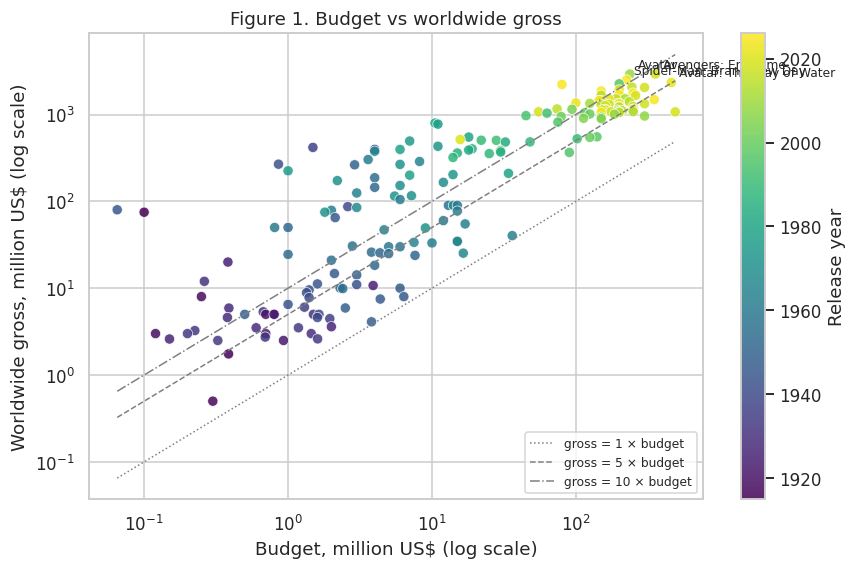

In [34]:
plot_df = films.dropna(subset=["budget", "worldwide_gross"])
fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(plot_df["budget"] / 1e6, plot_df["worldwide_gross"] / 1e6, c=plot_df["year"], cmap="viridis",
                s=45, alpha=0.85, edgecolor="white", linewidth=0.5)
x = np.logspace(np.log10(plot_df["budget"].min() / 1e6), np.log10(plot_df["budget"].max() / 1e6), 50)
for times, style in [(1, ":"), (5, "--"), (10, "-.")]:
    ax.plot(x, x * times, color="grey", ls=style, lw=1, label=f"gross = {times} × budget")
for _, row in plot_df.nlargest(4, "worldwide_gross").iterrows():
    ax.annotate(row["title"], (row["budget"] / 1e6, row["worldwide_gross"] / 1e6), xytext=(5, 4),
                textcoords="offset points", fontsize=8)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Budget, million US$ (log scale)")
ax.set_ylabel("Worldwide gross, million US$ (log scale)")
ax.set_title("Figure 1. Budget vs worldwide gross")
fig.colorbar(sc, ax=ax, label="Release year")
ax.legend(loc="lower right", fontsize=8)
fig.savefig(FIGURES / "fig1_budget_vs_gross.png")
plt.show()

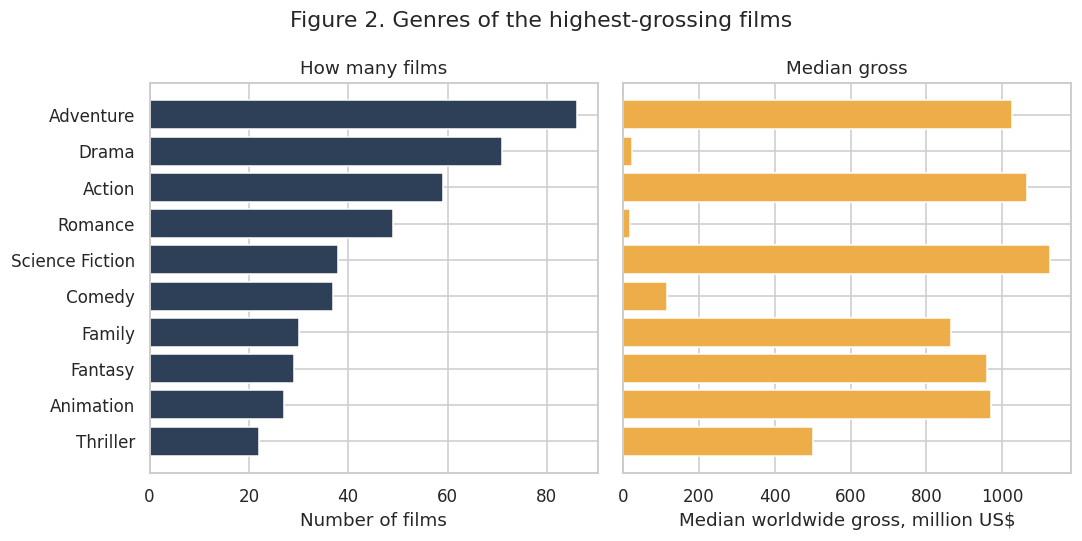

In [35]:
g = genre_stats.head(10).sort_values("films")
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
axes[0].barh(g.index, g["films"], color="#2e4057")
axes[0].set_xlabel("Number of films")
axes[0].set_title("How many films")
axes[1].barh(g.index, g["median_gross_musd"], color="#edae49")
axes[1].set_xlabel("Median worldwide gross, million US$")
axes[1].set_title("Median gross")
fig.suptitle("Figure 2. Genres of the highest-grossing films")
fig.tight_layout()
fig.savefig(FIGURES / "fig2_genres.png")
plt.show()

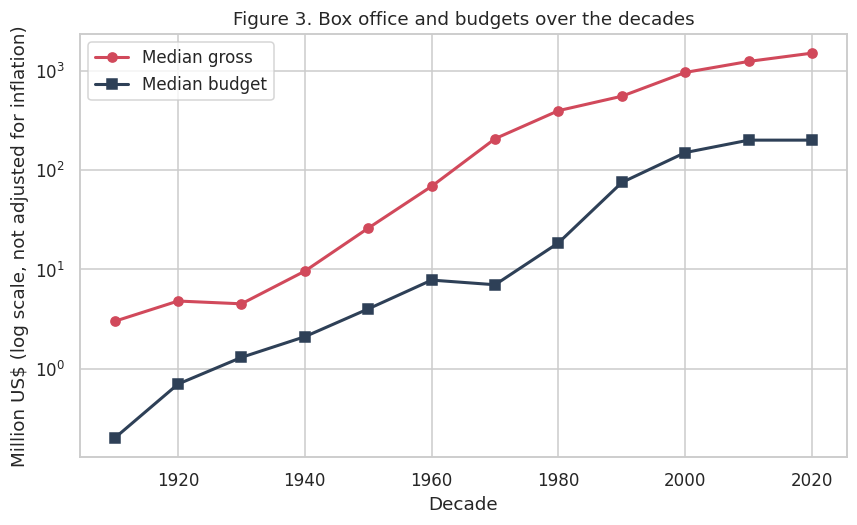

In [36]:
d = decade_stats.dropna(subset=["median_gross_musd"])
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(d.index.astype(int), d["median_gross_musd"], marker="o", lw=2, color="#d1495b", label="Median gross")
ax.plot(d.index.astype(int), d["median_budget_musd"], marker="s", lw=2, color="#2e4057", label="Median budget")
ax.set_yscale("log")
ax.set_xlabel("Decade")
ax.set_ylabel("Million US$ (log scale, not adjusted for inflation)")
ax.set_title("Figure 3. Box office and budgets over the decades")
ax.legend()
fig.savefig(FIGURES / "fig3_decades.png")
plt.show()

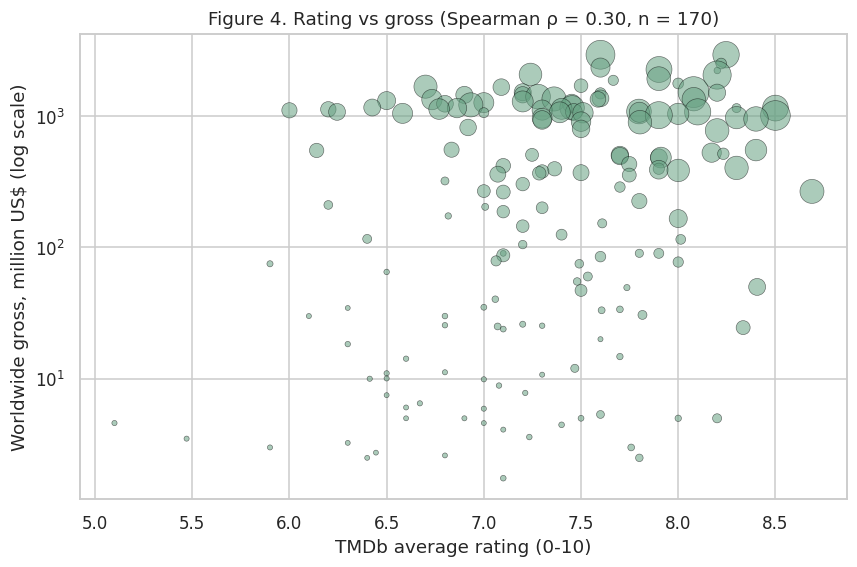

In [37]:
r_df = films.dropna(subset=["vote_average", "worldwide_gross", "vote_count"])
r_df = r_df[r_df["vote_count"] >= 50]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(r_df["vote_average"], r_df["worldwide_gross"] / 1e6, s=r_df["vote_count"] / r_df["vote_count"].max() * 400 + 10,
           alpha=0.55, color="#66a182", edgecolor="black", linewidth=0.4)
rho = r_df["vote_average"].corr(r_df["worldwide_gross"], method="spearman")
ax.set_yscale("log")
ax.set_xlabel("TMDb average rating (0-10)")
ax.set_ylabel("Worldwide gross, million US$ (log scale)")
ax.set_title(f"Figure 4. Rating vs gross (Spearman ρ = {rho:.2f}, n = {len(r_df)})")
fig.savefig(FIGURES / "fig4_rating_vs_gross.png")
plt.show()

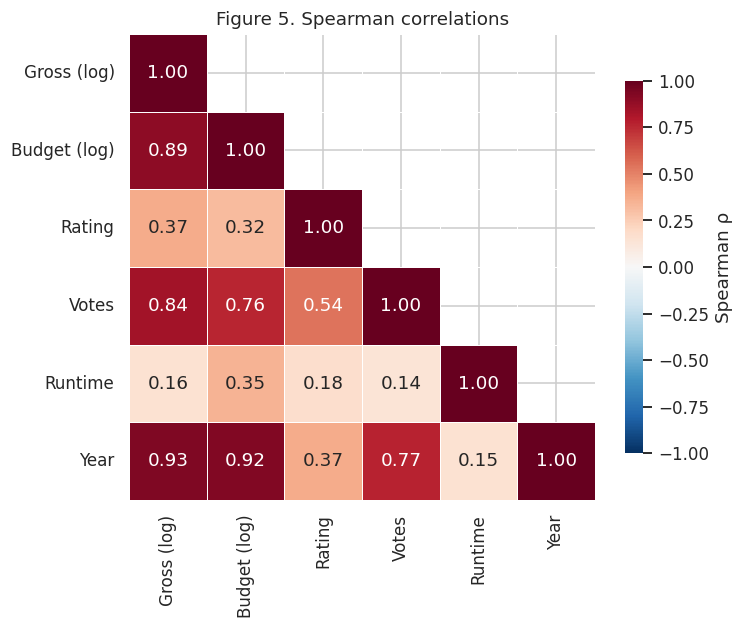

In [38]:
fig, ax = plt.subplots(figsize=(7, 5.5))
mask = np.triu(np.ones_like(spearman, dtype=bool), k=1)
sns.heatmap(spearman, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={"label": "Spearman ρ", "shrink": 0.8}, ax=ax)
ax.set_title("Figure 5. Spearman correlations")
fig.savefig(FIGURES / "fig5_correlations.png")
plt.show()

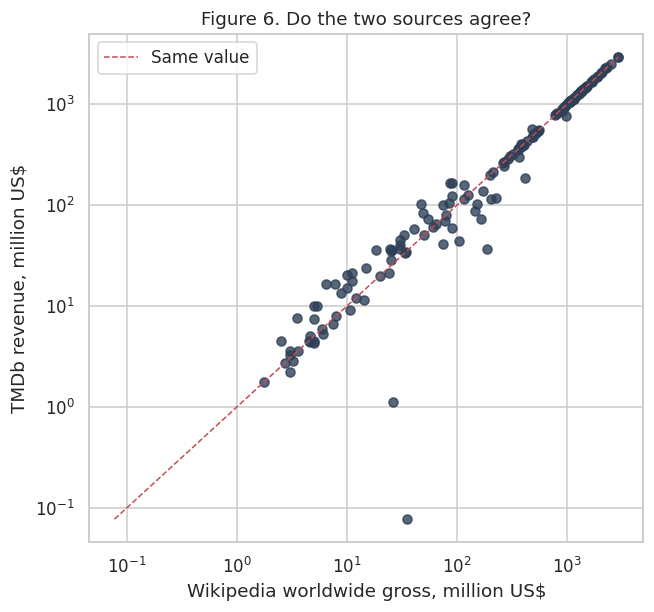

In [39]:
q = films.dropna(subset=["worldwide_gross", "revenue_tmdb"])
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(q["worldwide_gross"] / 1e6, q["revenue_tmdb"] / 1e6, s=35, alpha=0.8, color="#2e4057")
lims = [min(q["worldwide_gross"].min(), q["revenue_tmdb"].min()) / 1e6, max(q["worldwide_gross"].max(), q["revenue_tmdb"].max()) / 1e6]
ax.plot(lims, lims, "r--", lw=1, label="Same value")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Wikipedia worldwide gross, million US$")
ax.set_ylabel("TMDb revenue, million US$")
ax.set_title("Figure 6. Do the two sources agree?")
ax.legend()
fig.savefig(FIGURES / "fig6_source_agreement.png")
plt.show()